# Dimensionamiento de Talleres y Mantenimiento de Flota Ferroviaria

Este notebook traduce el script de R `Talleres.R` a Python para realizar la simulación estocástica de cálculo de vías de taller necesarias, trabajadores requeridos por tipo de mantenimiento (preventivo y correctivo) y porcentaje de disponibilidad de flota.


## 1. Importación de Librerías y Configuración Inicial


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Fijar semilla opcional para reproducibilidad
np.random.seed(42)


## 2. Bucle de Simulación de Monte Carlo


In [2]:
iterations = 10000  # Número de iteraciones

# Inicialización de matrices/vectores objetivo
nv = np.zeros((iterations, 2))  # Número de vías por tipo de mantenimiento (0: preventivo, 1: correctivo)
tm = np.zeros((iterations, 2))  # Número de trabajadores
DF = np.zeros(iterations)       # Disponibilidad de flota

f = 40  # Flota total de trenes
d = 365 # Número de días a estudiar

for z in range(iterations):
    ab = np.random.uniform(0.02, 0.03)  # % Absentismo laboral
    h = 8                                # Horas por turno
    v = 21 / 365                         # Vacaciones
    ht = 18                              # Horas de trabajo efectivo en taller por día
    htt = 8                              # Horas que un tren está en servicio
    
    # Cálculo de turnos diarios
    t = ht / (h * (1 - ab) * (5 / 7) * (1 - v))
    
    mp = np.random.uniform(0.09, 0.1)     # % Flota a mantenimiento preventivo
    mc = np.random.uniform(0.004, 0.005)  # % Flota a mantenimiento correctivo
    
    tll = f * np.array([mp, mc])          # Tasa de llegada de trenes a mantenimiento preventivo y correctivo al día
    DF[z] = 1 - mc                        # Disponibilidad de flota
    
    # Generación de datos diarios siguiendo distribución de Poisson
    mant_preventivos = np.random.poisson(tll[0], d)
    mant_correctivos = np.random.poisson(tll[1], d)
    
    tasa_llegada = np.ceil([np.mean(mant_preventivos), np.mean(mant_correctivos)])
    tasa_servicio = [np.random.uniform(4, 5), np.random.uniform(2, ht)]
    tiempo_servicio = [np.random.uniform(35, 40), 60 * np.abs(np.random.normal(0, 1))]
    
    # Cálculo de número de vías necesarias
    for i_type in range(2):
        nv[z, i_type] = (tll[i_type] / htt) / (1 / tasa_servicio[i_type])
        
    # Cálculo del número de trabajadores necesarios
    for i_type in range(2):
        tm[z, i_type] = nv[z, i_type] * t * (tiempo_servicio[i_type] / h)

print("Simulación completada con éxito.")


Simulación completada con éxito.


## 3. Resultados Generales


In [3]:
print(f"Para una flota total de: {f}")
print(f"Número de trabajadores necesarios para mantenimiento preventivo en un mes: {int(np.ceil(np.mean(tm[:, 0])))}")
print(f"Número de trabajadores necesarios para mantenimiento correctivo en un mes: {int(np.ceil(np.mean(tm[:, 1])))}")
print(f"Número de vías para taller tipo 1 (Preventivo): {int(np.ceil(np.mean(nv[:, 0])))}")
print(f"Número de vías para taller tipo 2 (Correctivo): {int(np.ceil(np.mean(nv[:, 1])))}")
print(f"Porcentaje de disponibilidad de la flota: {np.mean(DF) * 100:.2f}%")


Para una flota total de: 40
Número de trabajadores necesarios para mantenimiento preventivo en un mes: 35
Número de trabajadores necesarios para mantenimiento correctivo en un mes: 5
Número de vías para taller tipo 1 (Preventivo): 3
Número de vías para taller tipo 2 (Correctivo): 1
Porcentaje de disponibilidad de la flota: 99.55%


## 4. Visualización de Resultados (Boxplots de Vías de Taller)


/var/folders/db/bt0lzwjx41z9b19jjkz44b400000gn/T/ipykernel_25427/3444611218.py:4: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[0].boxplot(nv[:, 0], vert=True, patch_artist=True, boxprops=dict(facecolor='#66b3ff'))
/var/folders/db/bt0lzwjx41z9b19jjkz44b400000gn/T/ipykernel_25427/3444611218.py:14: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[1].boxplot(nv[:, 1], vert=True, patch_artist=True, boxprops=dict(facecolor='#ff9999'))


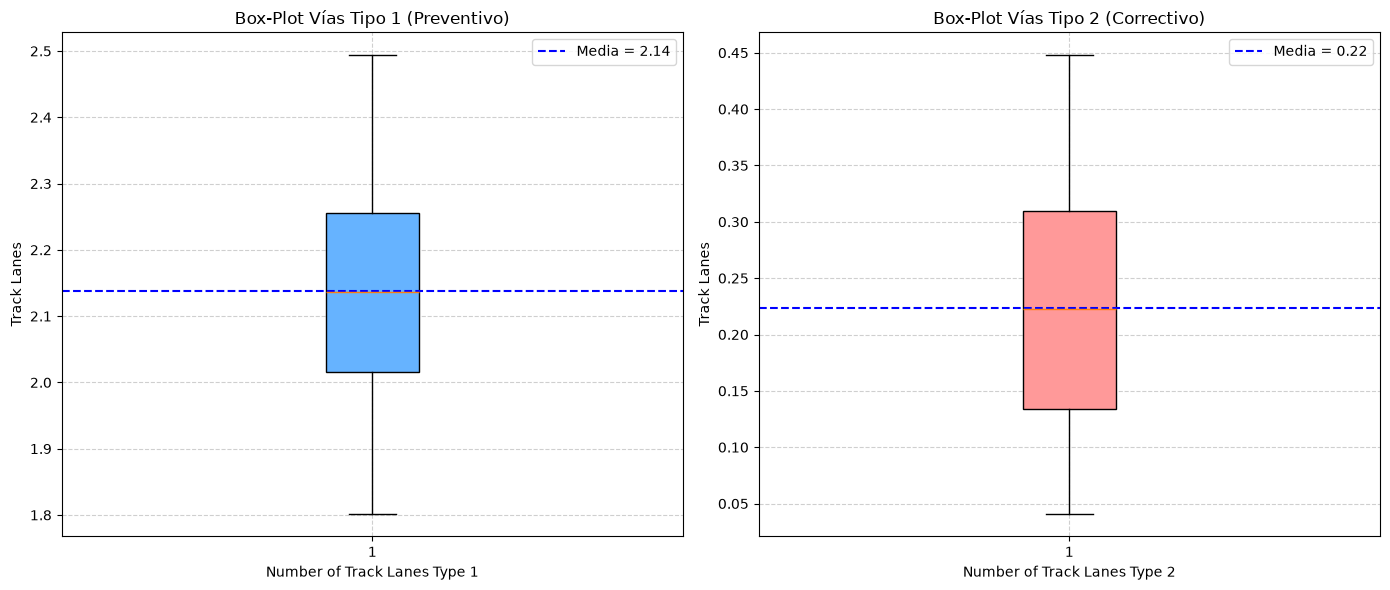

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Boxplot Vías Tipo 1 (Preventivo)
axes[0].boxplot(nv[:, 0], vert=True, patch_artist=True, boxprops=dict(facecolor='#66b3ff'))
media_nv1 = np.mean(nv[:, 0])
axes[0].axhline(y=media_nv1, color='blue', linestyle='--', label=f'Media = {media_nv1:.2f}')
axes[0].set_ylabel('Track Lanes')
axes[0].set_xlabel('Number of Track Lanes Type 1')
axes[0].set_title('Box-Plot Vías Tipo 1 (Preventivo)')
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.6)

# Boxplot Vías Tipo 2 (Correctivo)
axes[1].boxplot(nv[:, 1], vert=True, patch_artist=True, boxprops=dict(facecolor='#ff9999'))
media_nv2 = np.mean(nv[:, 1])
axes[1].axhline(y=media_nv2, color='blue', linestyle='--', label=f'Media = {media_nv2:.2f}')
axes[1].set_ylabel('Track Lanes')
axes[1].set_xlabel('Number of Track Lanes Type 2')
axes[1].set_title('Box-Plot Vías Tipo 2 (Correctivo)')
axes[1].legend()
axes[1].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()
